# Step 1 - Understand the data
- Identify the input features X and the target y.
- Explain what class 0 and class 1 mean.
- Check the number and proportion of observations in each class.
- Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 100)

df = pd.read_csv("../data/diabetes_binary_classification_data.csv")

print(f"rows: {df.shape[0]:,}   columns: {df.shape[1]}")
df.head()

rows: 253,680   columns: 22


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [76]:
df.corr()['Diabetes_binary'].sort_values(ascending=False)

# 1. Separate the classes
df_0 = df[df["Diabetes_binary"] == 0]
df_1 = df[df["Diabetes_binary"] == 1]

# 2. Find the size of the smaller class to get a 50/50 split
min_size = min(len(df_0), len(df_1))

# 3. Downsample both classes to match the minimum size
df_0_balanced = df_0.sample(n=min_size, random_state=42)
df_1_balanced = df_1.sample(n=min_size, random_state=42)

# 4. Combine them back into a balanced DataFrame
df_balanced = pd.concat([df_0_balanced, df_1_balanced]).sample(frac=1, random_state=42).reset_index(drop=True)

# 5. Calculate and compare correlations
corr_original = df.corr()["Diabetes_binary"]
corr_balanced = df_balanced.corr()["Diabetes_binary"]

# Create a comparison DataFrame
corr_comparison = pd.DataFrame({
    "Original_Dataset": corr_original,
    "Balanced_Dataset (50/50)": corr_balanced
}).sort_values(by="Balanced_Dataset (50/50)", ascending=False)

print(corr_comparison)


                      Original_Dataset  Balanced_Dataset (50/50)
Diabetes_binary               1.000000                  1.000000
GenHlth                       0.293569                  0.403482
HighBP                        0.263129                  0.382655
BMI                           0.216843                  0.287082
HighChol                      0.200276                  0.284526
Age                           0.177442                  0.274373
DiffWalk                      0.218344                  0.270656
PhysHlth                      0.171337                  0.211926
HeartDiseaseorAttack          0.177282                  0.207632
Stroke                        0.105816                  0.124924
CholCheck                     0.064761                  0.113663
MentHlth                      0.069315                  0.091290
Smoker                        0.060789                  0.084918
Sex                           0.031430                  0.042076
NoDocbcCost              

array([[<Axes: title={'center': 'Diabetes_binary'}>,
        <Axes: title={'center': 'HighBP'}>,
        <Axes: title={'center': 'HighChol'}>,
        <Axes: title={'center': 'CholCheck'}>,
        <Axes: title={'center': 'BMI'}>],
       [<Axes: title={'center': 'Smoker'}>,
        <Axes: title={'center': 'Stroke'}>,
        <Axes: title={'center': 'HeartDiseaseorAttack'}>,
        <Axes: title={'center': 'PhysActivity'}>,
        <Axes: title={'center': 'Fruits'}>],
       [<Axes: title={'center': 'Veggies'}>,
        <Axes: title={'center': 'HvyAlcoholConsump'}>,
        <Axes: title={'center': 'AnyHealthcare'}>,
        <Axes: title={'center': 'NoDocbcCost'}>,
        <Axes: title={'center': 'GenHlth'}>],
       [<Axes: title={'center': 'MentHlth'}>,
        <Axes: title={'center': 'PhysHlth'}>,
        <Axes: title={'center': 'DiffWalk'}>,
        <Axes: title={'center': 'Sex'}>, <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Education'}>,
        <Axes: title=

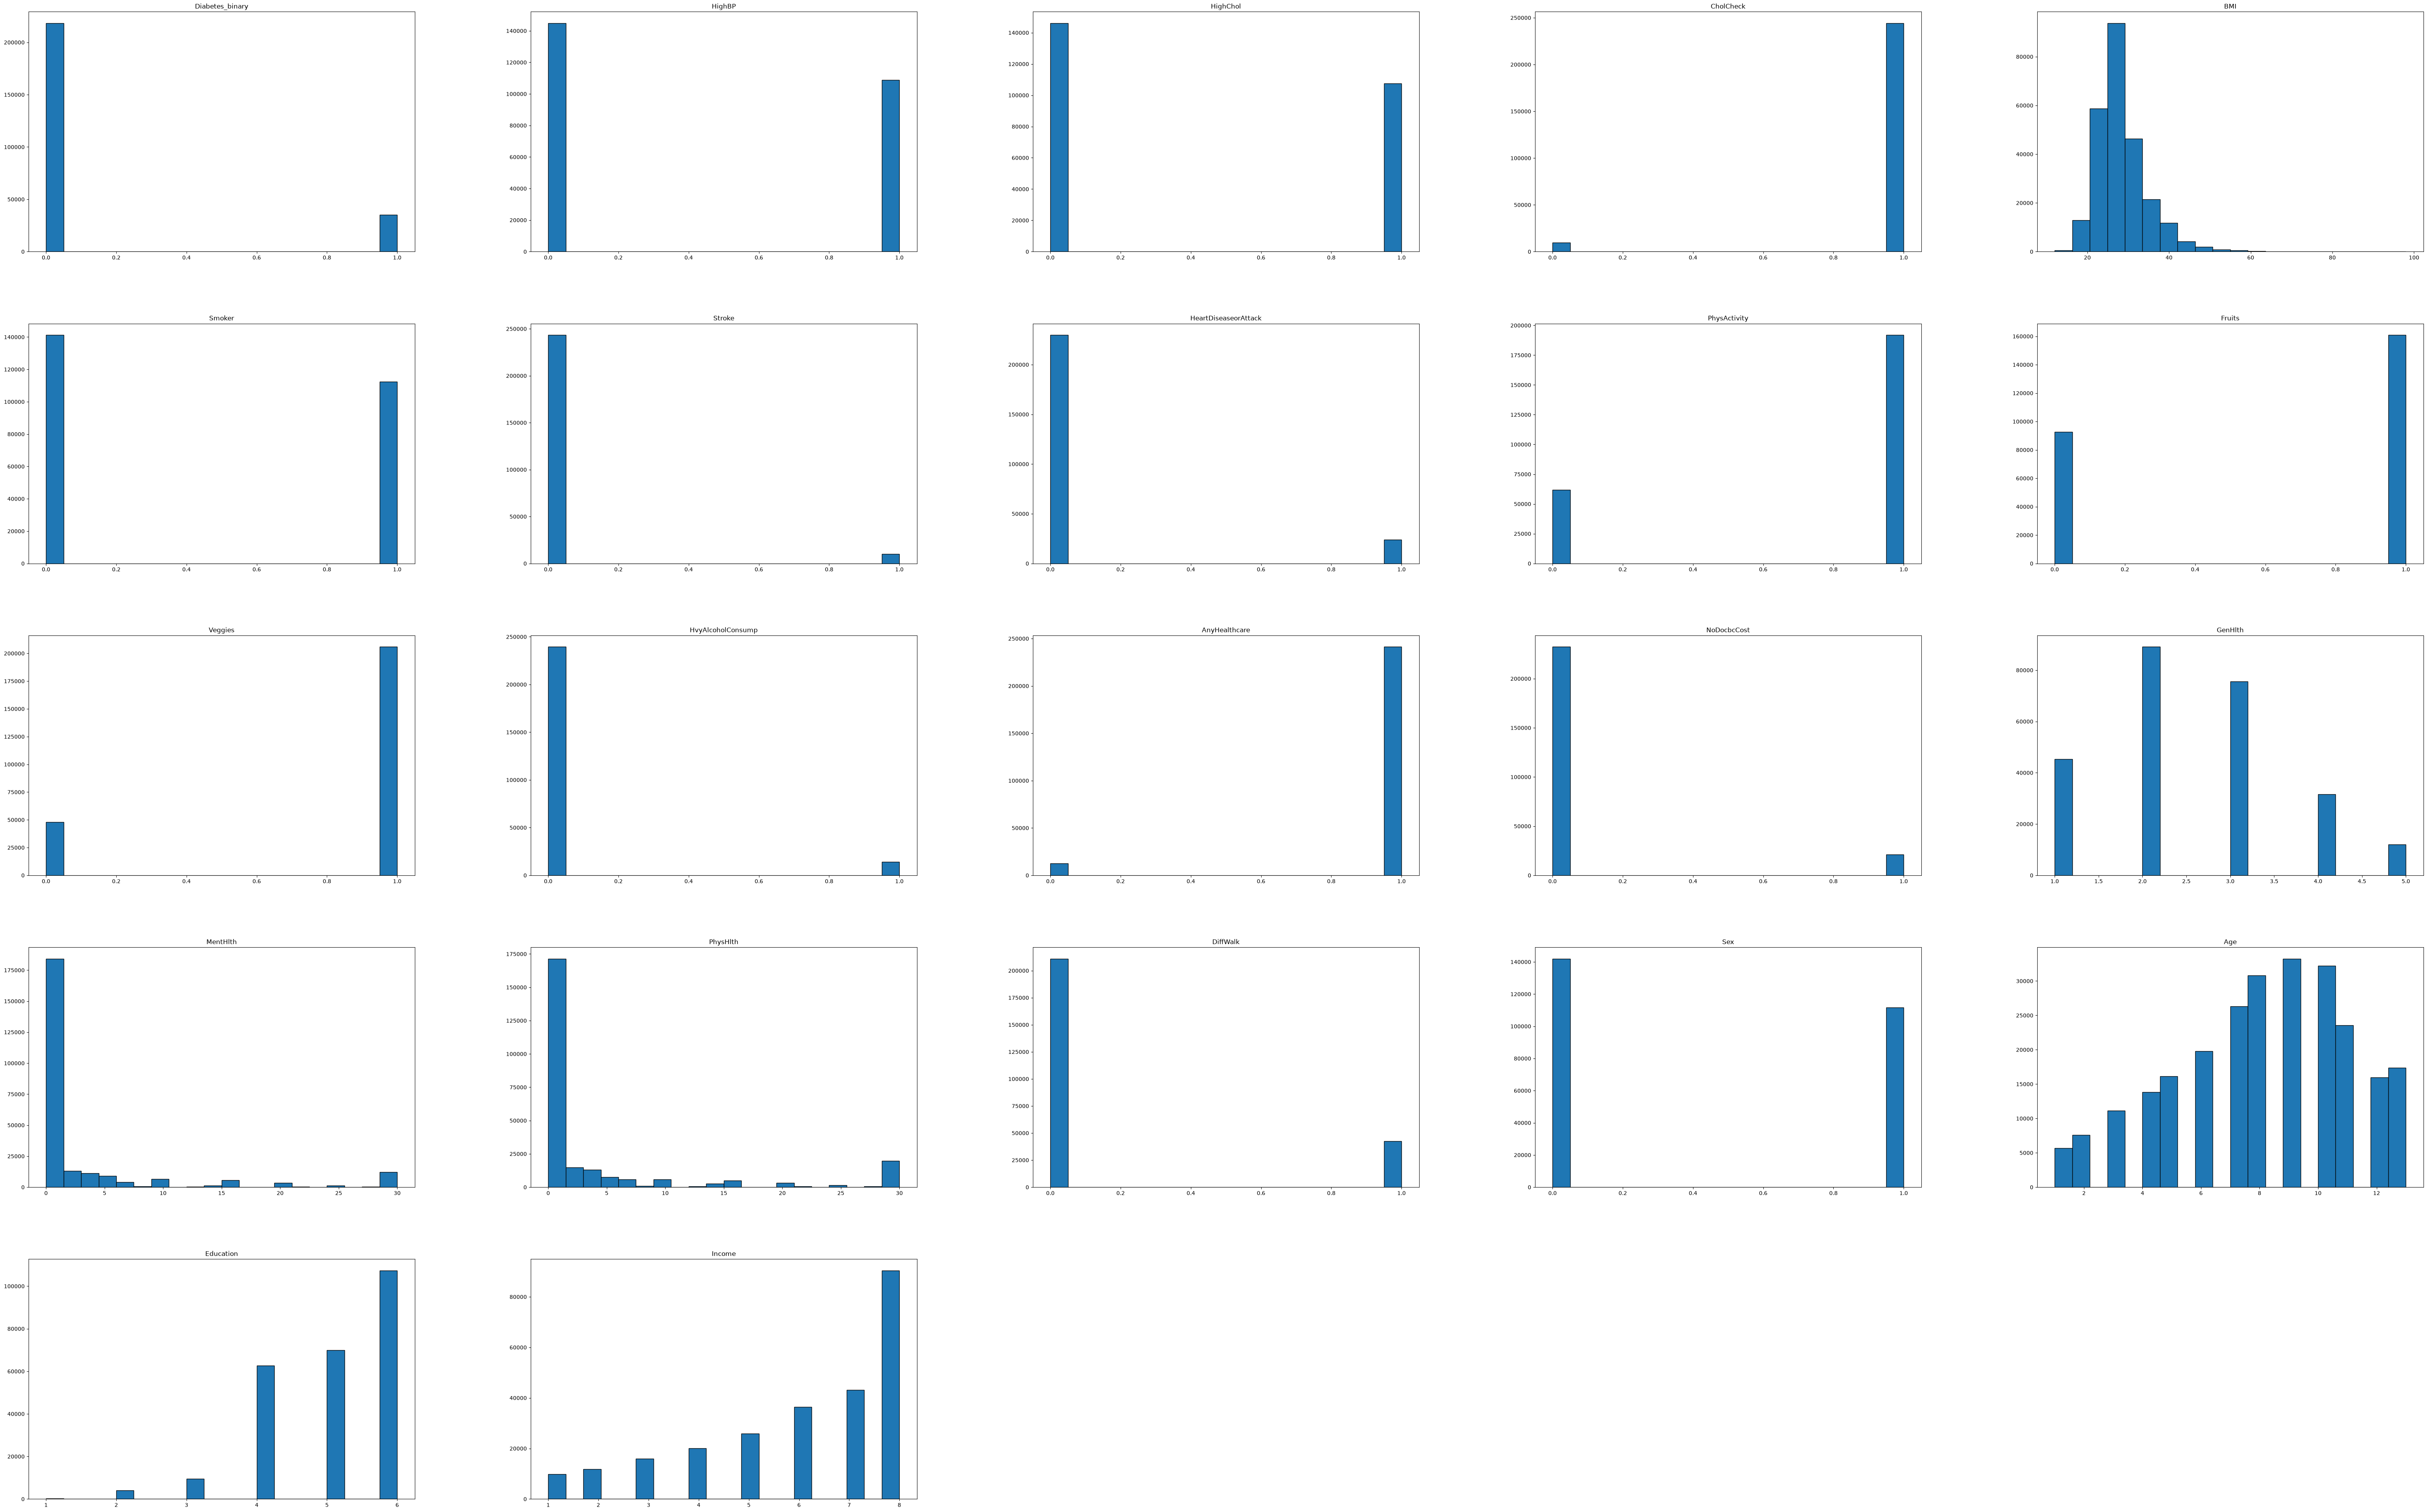

In [21]:
df.hist(bins=20, figsize=(80, 50), grid=False, edgecolor='black')

# Step 2 - Explore the data
Use EDA to investigate all input features and their relationships with Diabetes_binary. Choose plots or tables that are appropriate
for each type of feature:
- for numerical features, examine their distributions and compare them between the two target classes;
- for binary categorical features, examine counts/proportions and compare the proportion of Diabetes_binary across the two
categories;
- for ordered categorical features, examine how the distribution or proportion of Diabetes_binary changes across the ordered
categories.

Explore all input features, but focus your detailed interpretation on the most informative or interesting results. You may use loops
or functions where appropriate rather than repeating essentially identical code. For the results you discuss in detail, state the
question, show appropriate evidence, explain what you observe, and explain what the evidence allows you to conclude and what it
does not. Look for patterns such as differences between the two target classes, changes in the proportion of class 1 across
categories, unusual distributions, and features that appear to have little relationship with the target. Remember: EDA describes
associations and patterns in the observed data; an association does not show that one variable causes diabetes.

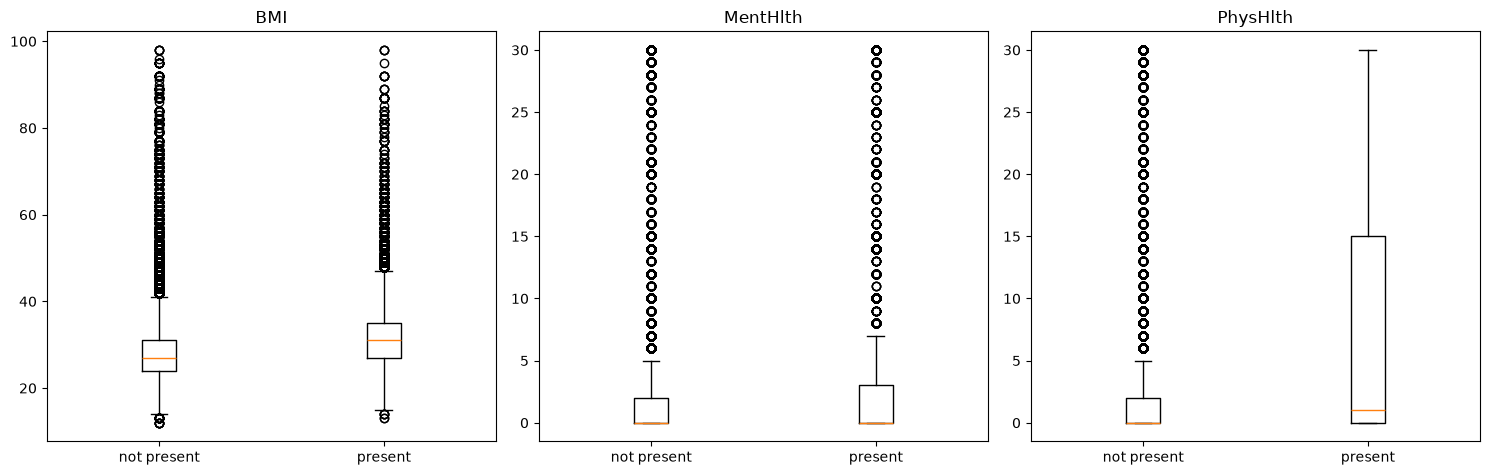

In [58]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

fig, ax = plt.subplots(1, len(numerical_features), figsize=(15, 5))

for a, col in zip(ax, numerical_features):
    a.boxplot([
        df.loc[df["Diabetes_binary"] == 0][col],
        df.loc[df["Diabetes_binary"] == 1][col],
    ], tick_labels=["not present", "present"])
    a.set_title(col) 
    a.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


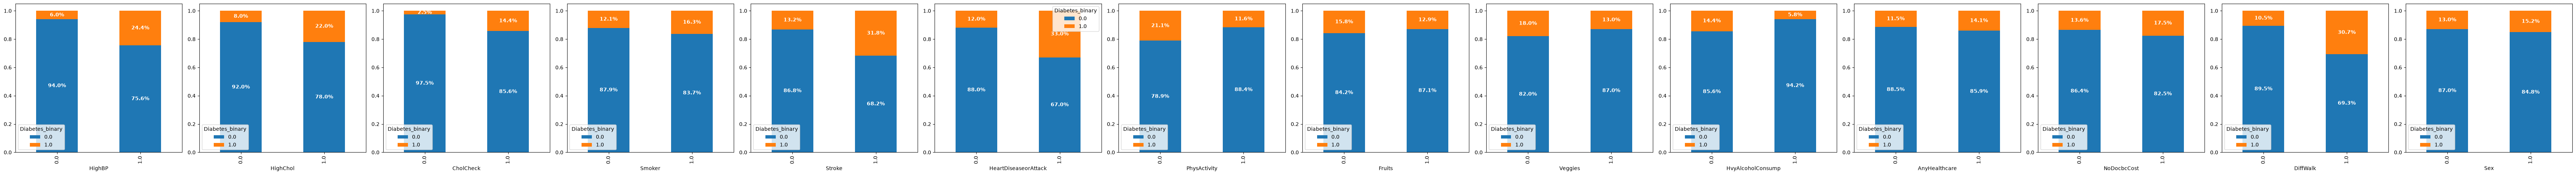

In [75]:
binary_features = [
    "HighBP", 
    "HighChol", 
    "CholCheck", 
    "Smoker", 
    "Stroke", 
    "HeartDiseaseorAttack", 
    "PhysActivity", 
    "Fruits", 
    "Veggies", 
    "HvyAlcoholConsump", 
    "AnyHealthcare", 
    "NoDocbcCost", 
    "DiffWalk", 
    "Sex"
]

fig, ax = plt.subplots(1, len(binary_features), figsize=(5*len(binary_features), 5))

for a, col in zip(ax, binary_features):

    # 1. Normalize by index so each column bar sums to 1.0 (100%)
    ct = pd.crosstab(df[col], df["Diabetes_binary"], normalize="index")
    
    # 2. Plot the stacked bar
    ct.plot(kind="bar", stacked=True, ax=a)
    
    # 3. Loop through bars to add percentage text labels
    for container in a.containers:
        # Get labels formatted as percentages (e.g., 45.2%)
        # Only display the label if the bar segment height is greater than 0
        labels = [f"{v.get_height()*100:.1f}%" if v.get_height() > 0 else '' for v in container]
        
        # Center the text inside each bar segment
        a.bar_label(container, labels=labels, label_type="center", color="white", fontweight="bold")

plt.suptitle("")
plt.tight_layout()
plt.show()


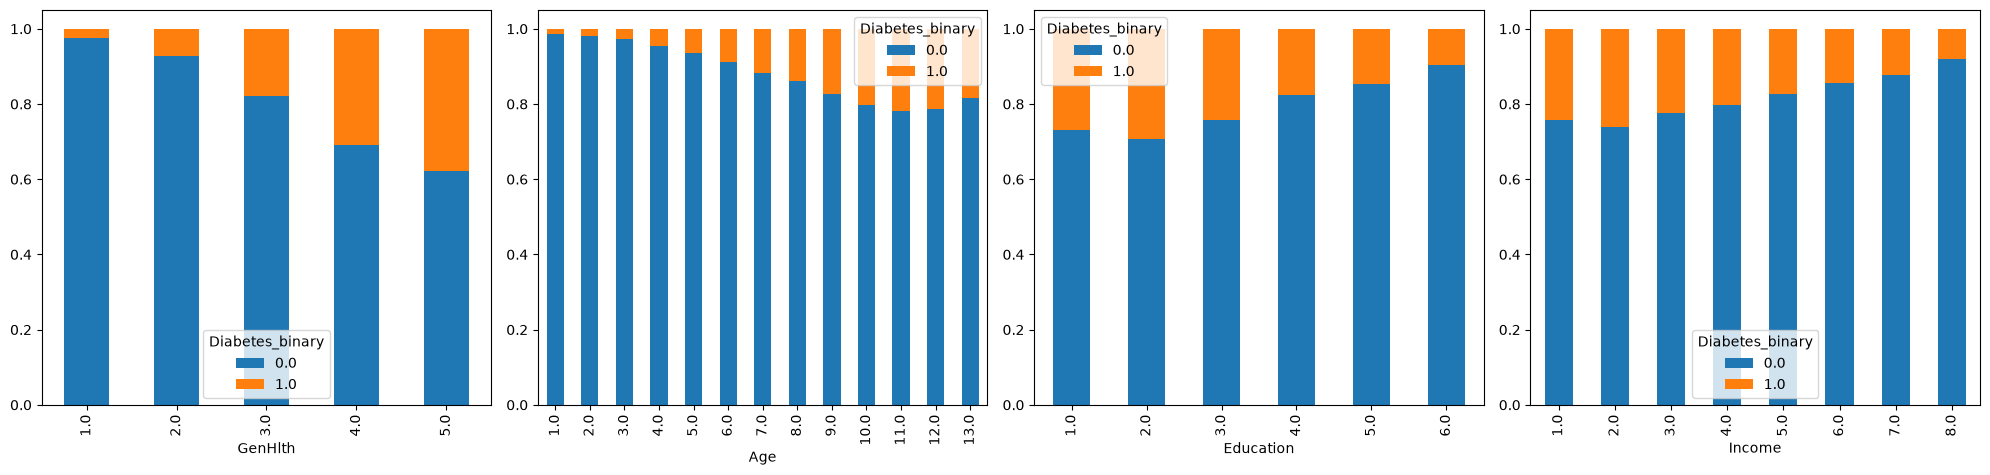

In [82]:
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

fig, ax = plt.subplots(1, len(ordinal_features), figsize=(5*len(ordinal_features), 5))

for  a, col in zip(ax, ordinal_features):
    ct = pd.crosstab(df[col], df['Diabetes_binary'], normalize='index')

    ax = ct.plot(kind='bar', stacked=True, ax = a)

plt.suptitle("")
plt.tight_layout()
plt.show()
